In [3]:
pip install torch numpy scikit-learn matplotlib

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------- ----------------------------- 2.1/8.4 MB 11.2 MB/s eta 0:00:01
   --------------------- ------------------ 4.5/8.4 MB 11.4 MB/s eta 0:00:01
   -------------------------------- ------- 6.8/8.4 MB 11.5 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 11.3 MB/s  0:00:00
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   -- ------------------------------------- 2.4/37.4 MB 11.7 MB/s eta 0:00:03
   ----- ---------------------------------- 4.7/37.4 MB 11.7 MB/s eta 0:00:03
   ------- -------------------------------- 7.1/37.4 MB 11.7 MB/s eta 0:00:03
   ---------- ----------------------------- 9.4/37.4 MB 11.7 MB/s eta 0:00:03
   ------------ --------------------------- 11.8/37.4 MB 11.7 MB/s eta 0:00:03
   --------------- ------------------------ 14.2/37.4 MB 11.7 MB/s eta 0:00:02
   ----------------- ---------------------- 16.8/37.4 MB 11.7 MB/s eta 0:00:02
   ----


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Epoch: 10000, Loss: 83.1419
Epoch: 20000, Loss: 83.1419
Epoch: 30000, Loss: 83.1419
Epoch: 40000, Loss: 83.1419
Epoch: 50000, Loss: 83.1419
Epoch: 60000, Loss: 83.1419
Epoch: 70000, Loss: 83.1419
Epoch: 80000, Loss: 83.1419
Epoch: 90000, Loss: 83.1419
Epoch: 100000, Loss: 83.1419
Epoch: 110000, Loss: 83.1419
Epoch: 120000, Loss: 83.1419
Epoch: 130000, Loss: 83.1419
Epoch: 140000, Loss: 83.1419
Epoch: 150000, Loss: 83.1419
Epoch: 160000, Loss: 83.1419
Epoch: 170000, Loss: 83.1419
Epoch: 180000, Loss: 83.1419
Epoch: 190000, Loss: 83.1419
Epoch: 200000, Loss: 83.1419
Epoch: 210000, Loss: 83.1419
Epoch: 220000, Loss: 83.1419
Epoch: 230000, Loss: 83.1419
Epoch: 240000, Loss: 83.1419
Epoch: 250000, Loss: 83.1419
Epoch: 260000, Loss: 83.1419
Epoch: 270000, Loss: 83.1419
Epoch: 280000, Loss: 83.1419
Epoch: 290000, Loss: 83.1419
Epoch: 300000, Loss: 83.1419
Epoch: 310000, Loss: 83.1419
Epoch: 320000, Loss: 83.1419
Epoch: 330000, Loss: 83.1419
Epoch: 340000, Loss: 83.1419
Epoch: 350000, Loss: 83

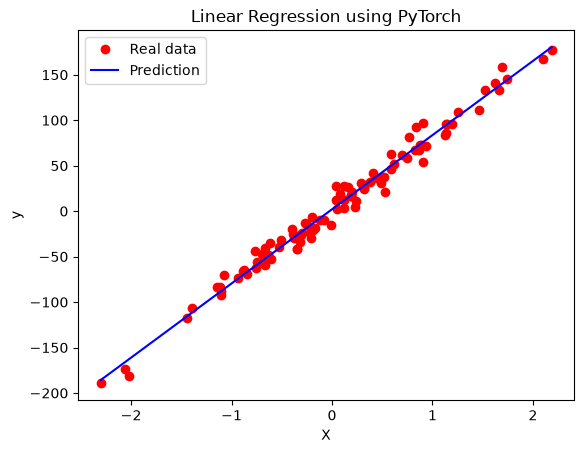

Weight: 81.5972671508789
Bias: 2.0270347595214844


In [1]:

import torch
import torch.nn as nn
import numpy as np
from sklearn import datasets
import matplotlib.pyplot as plt

# Step 0: Make data
X_numpy, y_numpy = datasets.make_regression(
    n_samples=100,
    n_features=1,
    noise=10,
    random_state=1
)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Convert NumPy arrays to PyTorch tensors
X = torch.from_numpy(X_numpy.astype(np.float32))
y = torch.from_numpy(y_numpy.astype(np.float32))
X = X.to(device)
y = y.to(device)
y = y.view(y.shape[0], 1)

# Find number of samples and features
number_of_samples, number_of_features = X.shape

# Step 1: Model
model = nn.Linear(number_of_features, 1).to(device)

# Step 2: Loss and optimizer
criterion = nn.MSELoss()

learning_rate = 0.01

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=learning_rate
)

# Step 3: Training loop
num_epochs = 500000

for epoch in range(num_epochs):
    # Clear old gradients
    optimizer.zero_grad()

    # Make predictions
    y_predicted = model(X)

    # Calculate loss
    loss = criterion(y_predicted, y)

    # Calculate gradients automatically
    loss.backward()

    # Update weight and bias
    optimizer.step()

    # Print loss every 10 epochs
    if (epoch + 1) % 10000 == 0:
        print(f"Epoch: {epoch + 1}, Loss: {loss.item():.4f}")

# Step 4: Make predictions after training
with torch.no_grad():
    predicted = model(X)

# Convert predictions to NumPy
predicted_numpy = predicted.cpu().numpy()

# Step 5: Sort data for a clean line
sorted_indices = np.argsort(X_numpy[:, 0])

X_sorted = X_numpy[sorted_indices]
predicted_sorted = predicted_numpy[sorted_indices]

# Step 6: Plot real data and predicted line
plt.plot(X_numpy, y_numpy, "ro", label="Real data")
plt.plot(X_sorted, predicted_sorted, "b-", label="Prediction")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear Regression using PyTorch")
plt.legend()
plt.show()

# Step 7: Display learned parameters
print("Weight:", model.weight.item())
print("Bias:", model.bias.item())
